---
title: Smoothing a noisy signal
subtitle: An executed Jupyter notebook, rendered by writer
authors: [Writer examples]
---

# Smoothing a noisy signal

## A noisy signal

Two periods of a sine wave plus noise, from a seeded generator.

In [1]:
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(seed=7)
t = np.linspace(0, 4 * np.pi, 200)
signal = np.sin(t) + rng.normal(scale=0.3, size=t.size)

print(f"{t.size} samples, mean {signal.mean():+.3f}, std {signal.std():.3f}")
print(f"warning: {(abs(signal) > 1.3).sum()} samples beyond ±1.3", file=sys.stderr)

200 samples, mean -0.040, std 0.721


## A rolling mean

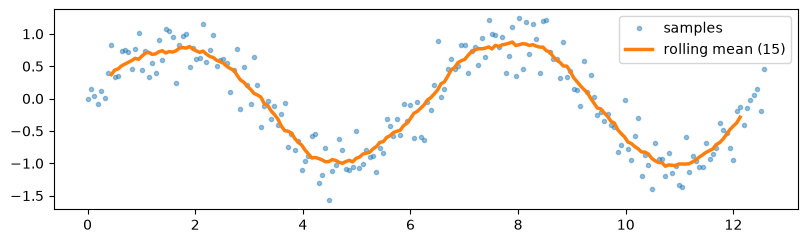

In [2]:
#| label: fig-rolling
#| fig-cap: A rolling mean smooths the noisy signal.
smooth = pd.Series(signal, index=t).rolling(15, center=True).mean()

fig, ax = plt.subplots(figsize=(9.6, 2.6), dpi=100, facecolor="white")
ax.plot(t, signal, ".", alpha=0.45, label="samples")
ax.plot(t, smooth, linewidth=2.5, label="rolling mean (15)")
ax.legend(loc="upper right")
plt.show()

The window in @fig-rolling is centred, so the curve does not lag behind the data. Its first and last seven points are missing: the window does not fit there.

## Summary statistics

In [3]:
#| tbl-cap: Summary statistics for the signal and rolling mean.
df = pd.DataFrame({"signal": signal, "smooth": smooth})
df["residual"] = df["signal"] - df["smooth"]
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
signal,200.0,-0.040,0.723,-1.572,-0.682,-0.030,0.597,1.240
smooth,186.0,-0.047,0.674,-1.046,-0.716,-0.007,0.646,0.874
residual,186.0,0.001,0.258,-0.598,-0.161,-0.012,0.176,0.760


## Every sample

In [4]:
for i in range(t.size):
    print(f"{i:3d}  t = {t[i]:6.3f}  signal = {signal[i]:+.3f}")

  0  t =  0.000  signal = +0.000
  1  t =  0.063  signal = +0.153
  2  t =  0.126  signal = +0.044
  3  t =  0.189  signal = -0.079
  4  t =  0.253  signal = +0.114
  5  t =  0.316  signal = +0.013
  6  t =  0.379  signal = +0.388
  7  t =  0.442  signal = +0.830
  8  t =  0.505  signal = +0.336
  9  t =  0.568  signal = +0.352
 10  t =  0.631  signal = +0.737
 11  t =  0.695  signal = +0.747
 12  t =  0.758  signal = +0.719
 13  t =  0.821  signal = +0.453
 14  t =  0.884  signal = +0.765
 15  t =  0.947  signal = +1.020
 16  t =  1.010  signal = +0.444
 17  t =  1.074  signal = +0.742
 18  t =  1.137  signal = +0.337
 19  t =  1.200  signal = +0.545
 20  t =  1.263  signal = +0.400
 21  t =  1.326  signal = +0.900
 22  t =  1.389  signal = +0.603
 23  t =  1.452  signal = +1.074
 24  t =  1.516  signal = +1.045
 25  t =  1.579  signal = +0.944
 26  t =  1.642  signal = +0.242
 27  t =  1.705  signal = +0.829
 28  t =  1.768  signal = +0.966
 29  t =  1.831  signal = +1.000
 30  t =  

## How the smoothing works

Each point becomes the mean of the $2k + 1$ samples centred on it, here $k = 7$:

$$
\bar{x}_i = \frac{1}{2k + 1} \sum_{j=-k}^{k} x_{i+j}
$$

In [5]:
from IPython.display import Markdown

noise = df["residual"].std()
display(Markdown(f"The residuals have a standard deviation of **{noise:.3f}**; "
                 "the noise we added has 0.3."))

The residuals have a standard deviation of **0.258**; the noise we added has 0.3.

## When a cell fails

A notebook keeps the traceback of a failed cell, and the document renders it too:

In [6]:
values = []
sum(values) / len(values)

ZeroDivisionError: division by zero